**Install the Optimization Library (PuLP)**

**Code-wise**: Google Colab already includes pandas for reading Excel files, so we only install PuLP—a beginner-friendly Python library for solving optimization problems. The -q flag keeps the installation output clean and quiet.

**Business-wise**: Before a supply chain analyst can design a factory network, they need a mathematical Solver capable of testing thousands of plant and shipping combinations to guarantee the lowest total cost.



In [ ]:
!pip install -q pulp

**Upload the 2026 European Dataset into Colab**

**Code-wise**: Because Google Colab runs on a cloud server, it cannot read files directly from your laptop until you upload them. files.upload() creates an interactive "Choose Files" button inside the notebook.

**Business-wise**: In real supply chain analytics, we keep business rates (labor, freight, rent, and customer demand) inside Excel spreadsheets separate from our Python code so planners can update quarterly numbers easily.

In [ ]:
from google.colab import files
import pandas as pd

# Click "Choose Files" when this runs and select EU_Supply_Chain_2026_Dataset_2.xlsx
uploaded = files.upload()

# Automatically grab the exact name of the file you just uploaded
DATA_FILE = list(uploaded.keys())[0]
print(f"Loaded file: {DATA_FILE}")

Saving EU_Supply_Chain_2026_Dataset.xlsx to EU_Supply_Chain_2026_Dataset (1).xlsx
Loaded file: EU_Supply_Chain_2026_Dataset (1).xlsx


**Read the Excel Tabs into Python Tables (DataFrames)**

**Code-wise**: pd.read_excel() reads each tab from the workbook. We use skiprows=3 to skip the top title rows so Row 4 becomes the column header, and index_col=0 so the 5 country names (Germany, France, Spain, Czechia, Poland) become row labels we can look up easily.

**Business-wise**: Every manufacturing network decision balances five core business inputs:

**var_prod_costs**: Cost to make 1 unit (labor + electricity + materials).

**freight_costs**: Cost to send 1 Full Truckload (FTL) between two countries.

**fixed_costs**: Monthly rent, management salaries, and equipment costs to keep a plant open (in thousands of €).

**capacity**: Maximum units a Low- or High-capacity factory can build per month (in thousands of units).

**demand**: How many units customers in each country buy every month.

In [ ]:
# Read the 5 core operational sheets from our 2026 workbook
var_prod_costs = pd.read_excel(DATA_FILE, sheet_name="variable_costs", skiprows=3, index_col=0)
freight_costs  = pd.read_excel(DATA_FILE, sheet_name="freight_costs",  skiprows=3, index_col=0)
fixed_costs    = pd.read_excel(DATA_FILE, sheet_name="fixed_cost",     skiprows=3, index_col=0)
capacity       = pd.read_excel(DATA_FILE, sheet_name="capacity",       skiprows=3, index_col=0)
demand         = pd.read_excel(DATA_FILE, sheet_name="demand",         skiprows=3, index_col=0)

# Quick check: display customer demand across our 5 European markets
demand

,Demand
Demand (Units/Month),
Germany,1850000
France,1150000
Spain,620000
Czechia,280000
Poland,600000


**Combine Production & Shipping into "Landed Cost" (€/Unit)**
**Code-wise**: pandas automatically divides every cell in the 5×5 freight_costs table by 1000 and adds it to the matching cell in var_prod_costs.

**Business-wise**: Low factory wages mean nothing if long-distance trucking eats the savings. By dividing the Full Truckload rate by 1,000 units per truck and adding it to manufacturing cost, we get the true Landed Cost of making 1 unit in Country A (rows) and delivering it to Country B (columns).

In [ ]:
# 1 Full Truckload (FTL) carries 1,000 units -> convert €/truck into €/unit
UNITS_PER_TRUCK = 1000
landed_cost = var_prod_costs + (freight_costs / UNITS_PER_TRUCK)

# Display the 5x5 Landed Cost table rounded to 2 decimal places
landed_cost.round(2)

,Germany,France,Spain,Czechia,Poland
Variable Costs (€/Unit),,,,,
Germany,13.99,14.93,16.01,14.24,15.25
France,14.51,13.57,14.90,14.72,15.43
Spain,12.30,11.61,10.20,12.63,13.51
Czechia,9.49,10.39,11.59,9.07,9.95
Poland,10.51,11.11,12.48,9.96,9.17


**Define the Decision Variables (PuLP)**

**Code-wise**: We import PuLP and create an empty minimization problem (LpMinimize). Then we define two dictionaries of unknown variables that the solver must figure out:ship_units[(i, j)]: Continuous numbers ($\ge 0$) representing how many units to ship from factory country i to customer market j.open_plant[(i, s)]: Binary switches (0 = Closed, 1 = Open) for building a Low or High capacity plant in country i.

**Business-wise**: Every supply chain network design comes down to two executive decisions:

  1. Strategic (Long-term): Which factories should we open, and what size should they be?

  2. Operational (Monthly): How many products should each open factory ship to each customer market?

In [ ]:
import pulp

# Create lists of our 5 countries and 2 factory size options
locations   = list(demand.index)   # ['Germany', 'France', 'Spain', 'Czechia', 'Poland']
plant_sizes = ['Low', 'High']

# Initialize the optimization model with the goal of minimizing total cost
model = pulp.LpProblem("EU_Supply_Chain_Network_2026", pulp.LpMinimize)

# Decision Variable 1: Monthly units produced in country 'i' and shipped to market 'j'
ship_units = {
    (i, j): pulp.LpVariable(f"ship_{i}_{j}", lowBound=0, cat="Continuous")
    for i in locations for j in locations
}

# Decision Variable 2: Binary switch (1 = Open plant, 0 = Keep closed) for country 'i' and size 's'
open_plant = {
    (i, s): pulp.LpVariable(f"plant_{i}_{s}", cat="Binary")
    for i in locations for s in plant_sizes
}

print(f"Created {len(ship_units)} shipping route variables and {len(open_plant)} factory decision variables.")

Created 25 shipping route variables and 10 factory decision variables.


**Set the Cost Formula (Objective) and Business Rules (Constraints)**

**Code-wise**: Using lpSum(), we add three components to model:

Objective Function: Total Fixed Plant Costs + Total Variable Production & Shipping Costs. (We multiply fixed_costs and capacity by 1000 because those Excel sheets are stored in thousands).

Rule 1 (Demand Constraint): For every customer country j, incoming shipments from all factories must equal demand.

Rule 2 (Capacity Constraint): For every producing country i, total outgoing shipments cannot exceed the combined capacity of the factories opened there.

**Business-wise**: A mathematical solver will cheat if you don't set realistic guardrails—for example, it would spend €0 by shutting down all factories and shipping nothing! These two rules force the model to satisfy 100% of customer demand while respecting physical factory production limits.

In [ ]:
# 1. OBJECTIVE FUNCTION: Minimize Total Monthly Cost (Fixed Plant Overhead + Variable Landed Costs)
total_fixed_cost = pulp.lpSum(
    fixed_costs.loc[i, s] * 1000 * open_plant[(i, s)]
    for i in locations for s in plant_sizes
)

total_variable_cost = pulp.lpSum(
    landed_cost.loc[i, j] * ship_units[(i, j)]
    for i in locations for j in locations
)

model += total_fixed_cost + total_variable_cost

# 2. CONSTRAINT 1 (Demand Satisfaction): Every market must receive 100% of its monthly demand
for j in locations:
    model += pulp.lpSum(ship_units[(i, j)] for i in locations) == demand.loc[j, "Demand"]

# 3. CONSTRAINT 2 (Plant Capacity Limit): A country cannot ship more units than its open plants can make
for i in locations:
    model += pulp.lpSum(ship_units[(i, j)] for j in locations) <= pulp.lpSum(
        capacity.loc[i, s] * 1000 * open_plant[(i, s)] for s in plant_sizes
    )

print("Objective function and business constraints added successfully.")

Objective function and business constraints added successfully.


**Run the Solver and Inspect the Optimal 2026 Network**

**Code-wise**: model.solve() runs the optimization engine (PULP_CBC_CMD(msg=0) hides messy technical logs). We then extract the winning values using .varValue and organize them into two clean pandas tables: Active Factories and Monthly Shipment Matrix.

**Business-wise**: Instead of raw solver text, executives need an actionable blueprint: which plants to open, which lanes to ship on, and the exact monthly budget (€).

In [ ]:
# Solve the optimization problem
model.solve(pulp.PULP_CBC_CMD(msg=0))

# Print high-level executive summary
status_text = "Optimal" if model.status == 1 else f"Status Code: {model.status}"
print("=" * 55)
print(f"Optimization Status : {status_text}")
print(f"Minimum Monthly Cost: €{int(round(pulp.value(model.objective))):,}")
print("=" * 55)

# Table A: Which plants should we open?
plant_plan = pd.DataFrame(
    [[int(round(open_plant[(i, s)].varValue)) for s in plant_sizes] for i in locations],
    index=locations,
    columns=["Open_Low_Plant", "Open_High_Plant"]
)
print("\n1. Recommended Factory Footprint (1 = Open, 0 = Closed):")
display(plant_plan)

# Table B: How many units should each factory ship to each country?
shipping_plan = pd.DataFrame(
    [[int(round(ship_units[(i, j)].varValue)) for j in locations] for i in locations],
    index=[f"From_{i}" for i in locations],
    columns=[f"To_{j}" for j in locations]
)
print("\n2. Monthly Shipment Allocation (Units/Month):")
display(shipping_plan)

Optimization Status : Optimal
Minimum Monthly Cost: €58,587,900

1. Recommended Factory Footprint (1 = Open, 0 = Closed):


,Open_Low_Plant,Open_High_Plant
Germany,0,0
France,0,0
Spain,1,0
Czechia,1,1
Poland,0,1



2. Monthly Shipment Allocation (Units/Month):


,To_Germany,To_France,To_Spain,To_Czechia,To_Poland
From_Germany,0,0,0,0,0
From_France,0,0,0,0,0
From_Spain,0,0,500000,0,0
From_Czechia,1850000,0,120000,30000,0
From_Poland,0,1150000,0,250000,600000


**Build a Reusable Optimization Function (run_supply_chain_model)**

**Code-wise**: Instead of copying and pasting the model 4 times or manually commenting out lines like the original tutorial, we wrap our solver inside a clean Python function run_supply_chain_model(). It accepts any modified cost, capacity, or $\text{CO}_2$ limit and returns a clean summary dictionary.

**Business-wise**: Supply chain leaders rarely make decisions from a single static forecast—they run Stress Tests to see if their factory network survives diesel price spikes, capacity expansions, or stricter EU emissions caps.

In [ ]:
# Load the 2026 carbon intensity table for our Sustainability scenario
co2_data = pd.read_excel(DATA_FILE, sheet_name="sustainability_co2", skiprows=3, index_col=0)

def run_supply_chain_model(scenario_name, var_df, freight_df, fixed_df, cap_df, demand_df, max_co2_tons=None):
    """Solves the 2026 EU Capacitated Facility Location Problem for any given scenario."""
    locs  = list(demand_df.index)
    sizes = ['Low', 'High']

    # Calculate landed cost (€/unit) for this specific scenario
    unit_landed_cost = var_df + (freight_df / 1000)

    # Initialize model
    prob = pulp.LpProblem(scenario_name.replace(" ", "_"), pulp.LpMinimize)

    # Decision variables (using explicit keyword arguments)
    ship = {
        (i, j): pulp.LpVariable(f"ship_{i}_{j}", lowBound=0, upBound=None, cat="Continuous")
        for i in locs for j in locs
    }
    plant = {
        (i, s): pulp.LpVariable(f"plant_{i}_{s}", lowBound=0, upBound=1, cat="Binary")
        for i in locs for s in sizes
    }

    # Objective: Fixed plant overhead + Variable production & transport costs
    fixed_total = pulp.lpSum(fixed_df.loc[i, s] * 1000 * plant[(i, s)] for i in locs for s in sizes)
    var_total   = pulp.lpSum(unit_landed_cost.loc[i, j] * ship[(i, j)] for i in locs for j in locs)
    prob += fixed_total + var_total

    # Constraint 1: Meet 100% of market demand
    for j in locs:
        prob += pulp.lpSum(ship[(i, j)] for i in locs) == demand_df.loc[j, "Demand"]

    # Constraint 2: Respect open plant capacities
    for i in locs:
        prob += pulp.lpSum(ship[(i, j)] for j in locs) <= pulp.lpSum(
            cap_df.loc[i, s] * 1000 * plant[(i, s)] for s in sizes
        )

    # Optional Constraint 3: Monthly Manufacturing CO2 Emissions Cap (in metric tons)
    if max_co2_tons is not None:
        total_co2_tons = pulp.lpSum(
            (co2_data.loc[i, "Unit_Prod_CO2_kg"] / 1000) * ship[(i, j)]
            for i in locs for j in locs
        )
        prob += total_co2_tons <= max_co2_tons

    # Solve silently
    prob.solve(pulp.PULP_CBC_CMD(msg=0))

    # Calculate resulting CO2 emissions and active plants for reporting
    actual_co2_tons = sum(
        (co2_data.loc[i, "Unit_Prod_CO2_kg"] / 1000) * ship[(i, j)].varValue
        for i in locs for j in locs
    )
    active_plants = [
        f"{i} ({s})" for i in locs for s in sizes if plant[(i, s)].varValue > 0.5
    ]

    return {
        "Scenario": scenario_name,
        "Total_Cost_EUR": int(round(pulp.value(prob.objective))),
        "Fixed_Cost_EUR": int(round(pulp.value(fixed_total))),
        "Variable_Cost_EUR": int(round(pulp.value(var_total))),
        "CO2_Emissions_Tons": int(round(actual_co2_tons)),
        "Open_Facilities": ", ".join(active_plants)
    }

print("Reusable scenario function ready!")

Reusable scenario function ready!


**Compare 4 Strategic 2026 Scenarios Side-by-Side**

**Code-wise**: We create .copy() versions of our DataFrames so modifying one scenario never corrupts the baseline data, run all 4 scenarios in a loop, and display the comparison in a single executive summary table.

**Business-wise**: We test four executive questions relevant to 2026 European manufacturing:
1. Baseline (2026 Current): Optimal footprint under current Eurostat & IRU rates.
2. Poland Mega-Hub Expansion: What if we double Poland's High-Capacity plant (2,000 -> 4,000 kUnits/mo, doubling its fixed cost) to centralize Eastern European production?
3. 3x Road Freight & Toll Surge: What if diesel spikes and stricter EU $\text{CO}_2$ truck tolls triple road freight costs?
4. Green Network (EU Carbon Cap ≤ 5,500 Tons/Mo): What if corporate ESG rules cap monthly manufacturing emissions, forcing production toward cleaner grids like France (48 gCO2/kWh) and Spain (135 gCO2/kWh) instead of coal-heavy Poland (560 gCO2/kWh)?

In [ ]:
results = []

# Scenario 1: Baseline 2026
results.append(run_supply_chain_model(
    "1. Baseline (2026)", var_prod_costs, freight_costs, fixed_costs, capacity, demand
))

# Scenario 2: Double Poland High-Capacity Plant
cap_s2   = capacity.copy()
fixed_s2 = fixed_costs.copy()
cap_s2.loc["Poland", "High"]   = 4000
fixed_s2.loc["Poland", "High"] = fixed_costs.loc["Poland", "High"] * 2
results.append(run_supply_chain_model(
    "2. Poland Mega-Hub (2x Cap)", var_prod_costs, freight_costs, fixed_s2, cap_s2, demand
))

# Scenario 3: 3x European Road Freight & Toll Surge
freight_s3 = freight_costs * 3
results.append(run_supply_chain_model(
    "3. Freight Surge (3x FTL)", var_prod_costs, freight_s3, fixed_costs, capacity, demand
))

# Scenario 4: EU Green Cap (Limit manufacturing CO2 to 5,500 tons/month)
results.append(run_supply_chain_model(
    "4. Green CO2 Cap (<=5,500t)", var_prod_costs, freight_costs, fixed_costs, capacity, demand, max_co2_tons=5500
))

# Build a clean Executive Comparison Table
summary_df = pd.DataFrame(results).set_index("Scenario")
summary_df["Cost_vs_Baseline_%"] = (
    (summary_df["Total_Cost_EUR"] - summary_df.loc["1. Baseline (2026)", "Total_Cost_EUR"])
    / summary_df.loc["1. Baseline (2026)", "Total_Cost_EUR"] * 100
).round(1)

display(summary_df)

,Total_Cost_EUR,Fixed_Cost_EUR,Variable_Cost_EUR,CO2_Emissions_Tons,Open_Facilities,Cost_vs_Baseline_%
Scenario,,,,,,
1. Baseline (2026),58587900,13500000,45087900,8808,"Spain (Low), Czechia (Low), Czechia (High), Po...",0.0
2. Poland Mega-Hub (2x Cap),57848400,10740000,47108400,10384,"Spain (Low), Poland (High)",-1.3
3. Freight Surge (3x FTL),69203700,13500000,55703700,8808,"Spain (Low), Czechia (Low), Czechia (High), Po...",18.1
"4. Green CO2 Cap (<=5,500t)",65842900,17460000,48382900,5182,"France (Low), Spain (Low), Spain (High), Czech...",12.4


**scenario comparison and the business trade-offs in the 2026 European network**

1. **Scenario 1 — Baseline (2026)**: €58.59M / month (8,808 tons $\text{CO}_2$)Opens Spain (Low), Czechia (Low + High), and Poland (High)—leveraging Central/Eastern European labor and rent advantages while keeping a regional plant in Spain to avoid 2,750 km truck hauls.

2. **Scenario 2 — Poland Mega-Hub (2x Capacity)**: €57.85M / month (-1.3%, 10,384 tons $\text{CO}_2$)Consolidating into Poland (High) + Spain (Low) saves €739,500/month by eliminating Czechia's fixed plant overhead, but increases carbon emissions by +17.9% because Poland has the highest grid carbon intensity (560 gCO2e/kWh).

3. **Scenario 3 — Freight Surge (3x FTL)**: €69.20M / month (+18.1%, 8,808 tons $\text{CO}_2$)Even when road freight triples, Eastern European manufacturing still beats opening high-cost plants in Germany or France—meaning your network absorbs a +€10.62M/month logistics shock rather than relocating facilities. (Tip: If you test 5x FTL, you can find the exact tipping point where Germany/France nearshoring becomes cheaper!)

4. **Scenario 4 — Green $\text{CO}_2$ Cap ($\le 5,500$ tons/mo)**: €65.84M / month (+12.4%, 5,182 tons $\text{CO}_2$)Cutting carbon emissions by 41.2% forces the solver to open plants in low-carbon France (48 gCO2e/kWh) and Spain (135 gCO2e/kWh), revealing an implied Carbon Abatement Cost of roughly €2,001 per ton of $\text{CO}_2$ avoided.

**Visualize Cost vs. Carbon Trade-Offs Across Scenarios**

**Code-wise**: We use matplotlib to build a clean two-panel executive chart from summary_df and save it as scenario_comparison.png (dpi=300) so it can be embedded directly in our GitHub README.

**Business-wise**: Executives rarely read raw tables in board meetings. Visuals immediately highlight the Cost–Sustainability Frontier—showing how centralizing in Poland cuts cost (-1.3%) at the expense of higher $\text{CO}_2$, while meeting a strict EU carbon cap shifts production toward France and Spain (+12.4% cost, -41.2% emissions).

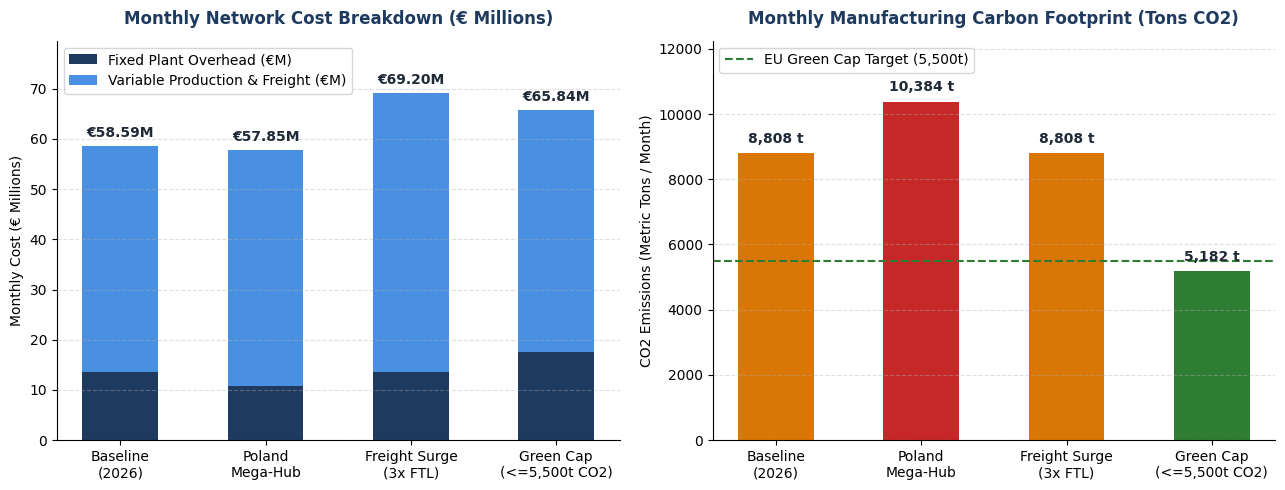

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare clean data in Millions of Euros (€M)
scenarios = ["Baseline\n(2026)", "Poland\nMega-Hub", "Freight Surge\n(3x FTL)", "Green Cap\n(<=5,500t CO2)"]
fixed_m   = summary_df["Fixed_Cost_EUR"] / 1e6
var_m     = summary_df["Variable_Cost_EUR"] / 1e6
totals_m  = summary_df["Total_Cost_EUR"] / 1e6
co2_tons  = summary_df["CO2_Emissions_Tons"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor("white")

# --- Left Panel: Stacked Bar Chart of Monthly Costs (€M) ---
x = np.arange(len(scenarios))
width = 0.52

bars1 = ax1.bar(x, fixed_m, width, label="Fixed Plant Overhead (€M)", color="#1E3A5F")
bars2 = ax1.bar(x, var_m, width, bottom=fixed_m, label="Variable Production & Freight (€M)", color="#4A90E2")

for idx, total in enumerate(totals_m):
    ax1.text(idx, total + 1.2, f"€{total:.2f}M", ha="center", va="bottom", fontweight="bold", fontsize=10, color="#1F2937")

ax1.set_title("Monthly Network Cost Breakdown (€ Millions)", fontsize=12, fontweight="bold", color="#1E3A5F", pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios, fontsize=10)
ax1.set_ylabel("Monthly Cost (€ Millions)", fontsize=10)
ax1.set_ylim(0, max(totals_m) * 1.15)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.legend(loc="upper left", frameon=True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- Right Panel: Monthly Manufacturing CO2 Emissions (Metric Tons) ---
colors_co2 = ["#2E7D32" if c <= 5500 else "#D97706" if c < 9500 else "#C62828" for c in co2_tons]
bars_co2 = ax2.bar(x, co2_tons, width, color=colors_co2)
ax2.axhline(5500, color="#2E7D32", linestyle="--", linewidth=1.5, label="EU Green Cap Target (5,500t)")

for idx, val in enumerate(co2_tons):
    ax2.text(idx, val + 220, f"{val:,} t", ha="center", va="bottom", fontweight="bold", fontsize=10, color="#1F2937")

ax2.set_title("Monthly Manufacturing Carbon Footprint (Tons CO2)", fontsize=12, fontweight="bold", color="#1E3A5F", pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(scenarios, fontsize=10)
ax2.set_ylabel("CO2 Emissions (Metric Tons / Month)", fontsize=10)
ax2.set_ylim(0, max(co2_tons) * 1.18)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(loc="upper left", frameon=True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("scenario_comparison.png", dpi=300, bbox_inches="tight")
plt.show()